Autores: Pedro Agrelo Márquez, Sneshanka Blanca Andrés Ochoa Grupo de prácticas: Grupo 15

# Entrenamiento de las CNNs

Este cuaderno lee los splits de train, val y test generados en el 
preprocesado, crea una CNN base y sus variantes para la comparación, y entrena 
todas ellas junto con redes preentrenadas. Se generan 
gráficas para documentar el proceso.

**Modelos comparados**:

- **12 CNN propias** (Base, Sin aumentación, Flatten, L2, Dropout, SGD, 2 y 4 bloques, 16 y 64 filtros, kernel 5x5 y convolución con stride 2)
- **4 preentrenadas** (DenseNet121 Feature Extraction, DenseNet121 Fine Tuning, ResNet50 Feature Extraction, ResNet50 Fine Tuning)

Al querer reducir el número de redes presentadas, se han fijado varios valores de hiperparámetros empiricamente sin incluirlos en un experimento. Por ello, solo se presentan los experimentos que más impacto tienen en las métricas finales.

In [1]:
# CONFIGURACIÓN

# Configuración para la ejecución en GPU 
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" # Silencia warnings
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true" # Evita errores de memoria al no reservarla de golpe
os.environ["TF_DETERMINISTIC_OPS"] = "1" # Operaciones deterministas para GPU
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0" # Elimina un warning 

import json
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score
import keras
from keras import layers, regularizers
import visualkeras

# Semilla para reproducibilidad
SEED = 42
keras.utils.set_random_seed(SEED)

RUTA_SPLIT = Path("eurosat_split")
SALIDA = Path("resultados_p2")
MODELOS = SALIDA / "modelos" # Guarda los checkpoints de cada modelo
CURVAS = SALIDA / "curvas"
RUTA_JSON = SALIDA / "resultados.json" # Se guardan las métricas para poder graficar sin tener que volver a entrenar los modelos
PESOS = "imagenet" # Pesos para las redes preentrenadas

SALIDA.mkdir(exist_ok=True)
MODELOS.mkdir(exist_ok=True)
CURVAS.mkdir(exist_ok=True)


resultados = []

# Carga de los splits
train = np.load(RUTA_SPLIT / "train.npz")
val = np.load(RUTA_SPLIT / "val.npz")
test = np.load(RUTA_SPLIT / "test.npz")

# Etiquetas sin one hot
X_train, y_train = train["X"], train["y"]
X_val, y_val = val["X"], val["y"]
X_test, y_test = test["X"], test["y"]

nombres_clases = [str(clase) for clase in np.load(RUTA_SPLIT / "class_names.npy")]
N_CLASES = len(nombres_clases)

# Comprobación del tamaño de las imágenes y el número de clases
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape) 
print("clases:", N_CLASES)

train (18900, 64, 64, 3) | val (4050, 64, 64, 3) | test (4050, 64, 64, 3)
clases: 10


### Data augmentation

Antes de entrenar se define y se visualiza la aumentación de datos (flips, rotación y zoom). Esto se hace para que el dataset aumente su diversidad y el tamaño del conjunto de entrenamiento para evitar el overfitting (al no tener un dataset significativamente grande), obligando a la red a extraer patrones más robustos para la generalización ante nuevas imágenes. 

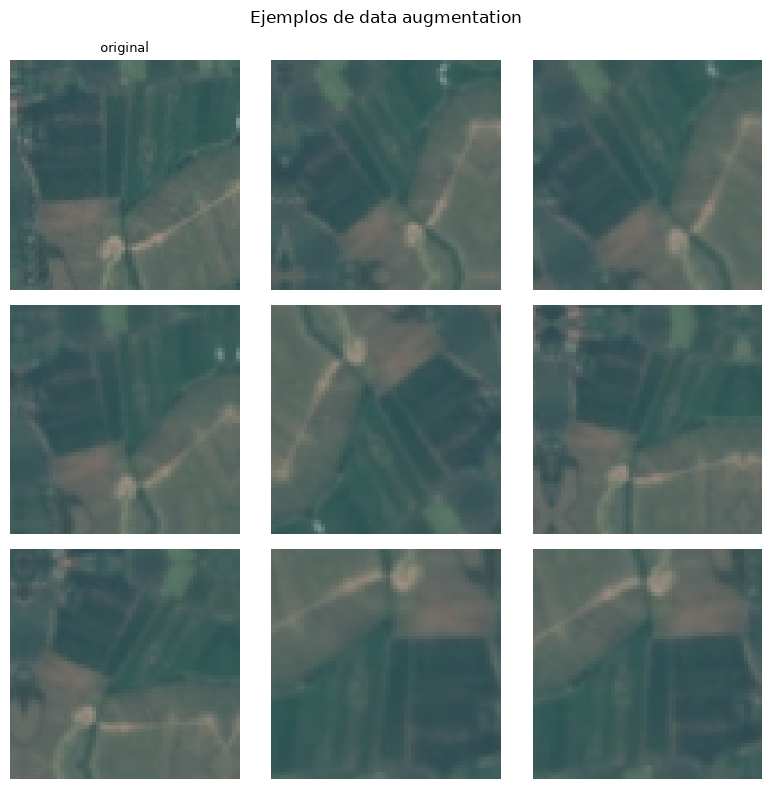

In [2]:
def crear_aumentacion():
    "Crea una aumentación nueva en cada llamada"
    return keras.Sequential(
    [      
        # Se generan flips de forma aleatoria tanto en horizontal como en vertical 
        layers.RandomFlip("horizontal_and_vertical"),
        # Se rotan las imágenes hasta 0.1 vueltas
        layers.RandomRotation(0.1),
        # Se amplían / reducen las imágenes un 20% 
        layers.RandomZoom(0.2),
    ]
)

# Visualización de la aumentación sobre una misma imagen 
data_augmentation = crear_aumentacion()
imagen = X_train[:1].astype("float32")
plt.figure(figsize=(8, 8))
ax = plt.subplot(3, 3, 1)
plt.imshow(imagen[0].astype("uint8"))
plt.title("original", fontsize=9)
plt.axis("off")
for i in range(8):
    aumentada = data_augmentation(imagen, training=True)
    ax = plt.subplot(3, 3, i + 2)
    plt.imshow(np.array(aumentada[0]).astype("uint8"))
    plt.axis("off")
plt.suptitle("Ejemplos de data augmentation")
plt.tight_layout()
plt.savefig(SALIDA / "fig0_ejemplos_augmentation.png", dpi=150)
plt.show()

### Definición de modelos y utilidades

Se definen funciones para el entrenamiento de los modelos. Se ha decidido utilizar Batch normalization tras cada convolución ya que eliminarlo obligaría a rediseñar el bloque (lo cual no sería un experimento aislado). También se añade Early Stopping sobre el loss de validación con una paciencia fija de 5 epochs (1/6 de los epochs totales, se asume que el modelo deja de mejorar tras ese número de epochs), ya que experimentar sobre la paciencia sería hacer overfitting del hiperparámetro sobre el conjunto de validación.

In [3]:
def reiniciar():
    keras.backend.clear_session() # Limpia la memoria y el estado global de Keras
    keras.utils.set_random_seed(SEED) # Reinicia las semillas de python, numpy y tensorflow

def bloque(x, filtros, kernel=3, pooling="max", l2=0.0):
    """Dos convoluciones + pooling='max' o 'stride'."""
    reg = regularizers.l2(l2) if l2 > 0 else None

    for _ in range(2):
        x = layers.Conv2D(filters=filtros, kernel_size=kernel,padding="same", use_bias=False, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)

    # Downsampling: MaxPool fijo o convolución con stride 2
    if pooling == "max":
        x = layers.MaxPooling2D(pool_size=2)(x)
    elif pooling == "stride":
        x = layers.Conv2D(filters=filtros, kernel_size=3, strides=2, padding="same", use_bias=False, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x


def crear_cnn(filtros=32, head="gap", dropout=0.3, aug=True, n_bloques=3, kernel=3, pooling="max", l2=0.0):
    """CNN configurable"""
    reg = regularizers.l2(l2) if l2 > 0 else None
    inputs = keras.Input(shape=(64, 64, 3))
    x = inputs
    if aug:
        x = crear_aumentacion()(x)
    x = layers.Rescaling(1.0 / 255)(x)

    for i in range(n_bloques):
        x = bloque(x, filtros * 2 ** i, kernel=kernel, pooling=pooling, l2 = l2)

    if head == "gap":
        x = layers.GlobalAveragePooling2D()(x)
    else:
        x = layers.Flatten()(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)

    outputs = layers.Dense(N_CLASES, activation="softmax",kernel_regularizer=reg)(x)
    return keras.Model(inputs=inputs, outputs=outputs)

# Modelos preentrenados, cada uno entrenado con un preprocesado distinto:
# DenseNet: escala a [0,1] y normaliza con media/desviación de ImageNet.
# ResNet50: pasa RGB->BGR y resta la media por canal.
PREENTRENADAS = {
    "DenseNet121": (keras.applications.DenseNet121, keras.applications.densenet.preprocess_input),
    "ResNet50": (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input),
}


def crear_preentrenado(nombre):
    """Transfer learning"""
    constructor, preprocesar = PREENTRENADAS[nombre]

    # include_top=False: se descarta el clasificador de 1000 clases de ImageNet.
    # input_shape=(96,96,3): se sube la resolución de 64 a 96 porque estas redes están
    # pensadas para imágenes mayores.
    conv_base = constructor(weights=PESOS, include_top=False, input_shape=(96, 96, 3))
    conv_base.trainable = False # No se modifican sus pesos para feature extraction
    
    inputs = keras.Input(shape=(64, 64, 3))
    x = crear_aumentacion()(inputs)
    x = layers.Resizing(96, 96)(x) # Reescala las imagenes
    x = preprocesar(x) # Preprocesa según la red
    x = conv_base(x, training=False) # Training false para que se utilicen sus estadísticas preentrenadas
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(N_CLASES, activation="softmax")(x)

    # Se devuelve también conv_base para poder hacer fine tuning
    return keras.Model(inputs, outputs), conv_base

def crear_callbacks(ruta):
    """Guarda en disco el mejor checkpoint de cada modelo (el de mejor val_loss).
    Si val_loss no mejora en 5 epoch seguidas para el entrenamiento"""
    return [
        keras.callbacks.ModelCheckpoint(filepath=ruta, save_best_only=True, monitor="val_loss"),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ]


def plot_curvas(history, nombre):
    """Curvas de accuracy y loss. Training azul, validation naranja."""
    acc = history['accuracy']
    val_acc = history['val_accuracy']
    loss = history['loss']
    val_loss = history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(10, 4))
    # Imagen izquierda (accuracy de train vs val)
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-', label='Training accuracy')
    plt.plot(epochs, val_acc, color='tab:orange', linestyle='-', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.legend()

    # Imagen derecha (loss de train vs val)
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-', label='Training loss')
    plt.plot(epochs, val_loss, color='tab:orange', linestyle='-', label='Validation loss')
    plt.title('Training and validation loss')
    plt.xlabel('Epochs')
    plt.legend()

    plt.suptitle(nombre, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    # Se genera el nombre del archivo en base al modelo
    archivo = CURVAS / (re.sub(r"[^a-z0-9]+", "_", nombre.lower()).strip("_") + ".png")
    plt.savefig(archivo, dpi=150)
    plt.show()


def evaluar(ruta, nombre, preentrenado, historial, t_inicio, monitor="val_loss", desde = 0):
    """Evalúa el modelo, lo añade a `resultados` y actualiza el JSON."""
    modelo = keras.models.load_model(ruta) # Se carga el mejor modelo

    _, acc_train = modelo.evaluate(X_train, y_train, batch_size=256, verbose=0)
    _, acc_val = modelo.evaluate(X_val, y_val, batch_size=256, verbose=0)

    pred = modelo.predict(X_test, batch_size=256, verbose=0).argmax(axis=1)
    matriz_confusion = confusion_matrix(y_test, pred, labels=range(N_CLASES))
    f1s = f1_score(y_test, pred, labels=range(N_CLASES), average=None, zero_division=0)
    f1_macro = f1_score(y_test, pred, average="macro", zero_division=0)

    # Época del mejor valor de la métrica monitorizada (loss o accuracy)
    # Cada métrica tiene una lista por epoch del modelo, desde únicamente para fine tuning (sólo sus propias epochs, no las de fe)
    valores = historial[monitor][desde:] 
    if monitor.endswith("loss"):
        mejor_epoca = int(np.argmin(valores)) + 1 + desde
    else:
        mejor_epoca = int(np.argmax(valores)) + 1 + desde

    resultado = {
        "nombre": nombre, "preentrenado": preentrenado, "params": int(modelo.count_params()),
        "tiempo": round(time.time() - t_inicio, 1), "acc_train": float(acc_train),
        "acc_val": float(acc_val), "acc_test": float((pred == y_test).mean()),
        "f1_macro": float(f1_macro), "f1_clases": f1s.tolist(),
        "matriz": matriz_confusion.tolist(),
        "mejor_epoca": mejor_epoca,
        "historial": {k: [float(v) for v in vals] for k, vals in historial.items()},
    }
    resultados.append(resultado)
    print(f">> {nombre}: train={acc_train:.4f} val={acc_val:.4f} test={resultado['acc_test']:.4f} "
          f"(mejor época = {mejor_epoca}, {monitor} = {historial[monitor][mejor_epoca-1]:.4f})")

    with open(RUTA_JSON, "w") as f:
        json.dump(resultados, f, indent=4)

    return resultado

## Entrenamiento de las CNN propias

Todas comparten semilla, batch de 64, learning rate (en Adam, 1e-4 ajustado empíricamente al observar una variación excesiva en validación con 1e-3) y número máximo de epochs (30 si no ocurre earlystopping). Se divide en 2 análisis: Uno en el que se cambia solamente un componente respecto a la base (sin aumentación, flatten, dropout, l2 y optimizador SGD) y otro en el que se comparan diferentes arquitecturas de la CNN (filtros, pooling, profundidad y kernel).

### Análisis de componentes
Para este análisis se parte de una red base, en la que se utilizan componentes estándar (dropout, aumentación, gap y Adam). En cada variación se analiza y justifica el efecto de su ausencia (adición en caso de L2 y sustitución en caso de SGD) en la red.
Se usa dropout 0.3, valor bajo porque, aunque el dataset sea reducido, la red es simple y se quieren evitar infraajustes (comprobados empíricamente). Valores más altos podrían hacer que la red no aprendiera (muy restrictivos al apagar muchas neuronas).

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 289,642 (1.10 MB)

 Trainable params: 288,746 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/30
296/296 - 16s - 54ms/step - accuracy: 0.5950 - loss: 1.1762 - val_accuracy: 0.2158 - val_loss: 3.1642
Epoch 2/30
296/296 - 12s - 39ms/step - accuracy: 0.7213 - loss: 0.7951 - val_accuracy: 0.6748 - val_loss: 0.9118
Epoch 3/30
296/296 - 13s - 43ms/step - accuracy: 0.7579 - loss: 0.6957 - val_accuracy: 0.7556 - val_loss: 0.7298
Epoch 4/30
296/296 - 12s - 39ms/step - accuracy: 0.7794 - loss: 0.6354 - val_accuracy: 0.7202 - val_loss: 0.8752
Epoch 5/30
296/296 - 12s - 39ms/step - accuracy: 0.7961 - loss: 0.5875 - val_accuracy: 0.7180 - val_loss: 0.8188
Epoch 6/30
296/296 - 12s - 42ms/step - accuracy: 0.8104 - loss: 0.5493 - val_accuracy: 0.7452 - val_loss: 0.7592
Epoch 7/30
296/296 - 12s - 40ms/step - accuracy: 0.8213 - loss: 0.5155 - val_accuracy: 0.7654 - val_loss: 0.6571
Epoch 8/30
296/296 - 13s - 42ms/step - accuracy: 0.8316 - loss: 0.4903 - val_accuracy: 0.7511 - val_loss: 0.6994
Epoch 9/30
296/296 - 12s - 40ms/step - accuracy: 0.8410 - loss: 0.4636 - val_accuracy: 0.8030 - 

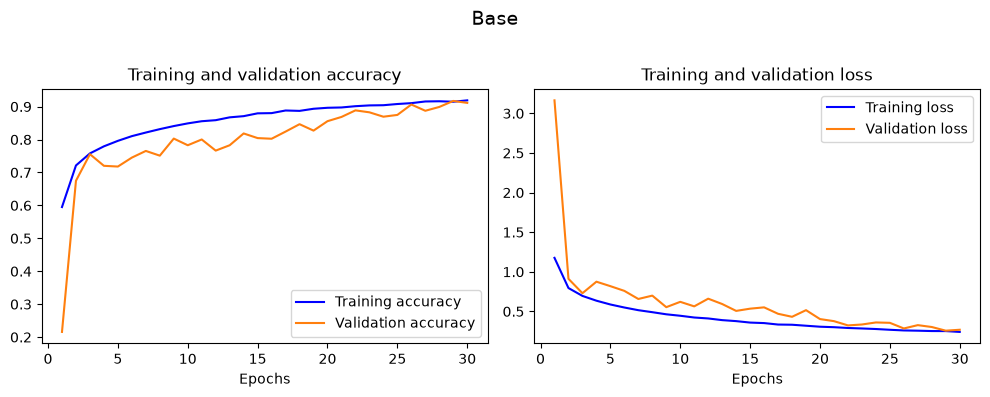

In [4]:
# CNN BASE
reiniciar()
t0 = time.time() # Cronometra para medir el tiempo de entrenamiento

ruta = str(MODELOS / "base.keras")
model = crear_cnn()

# Visualizar las capas del modelo, en el análisis de componentes solo en la base
model.summary()
visualkeras.layered_view(model, legend=True)

# Como las etiquetas son enteras, se usa sparse categorical crossentropy. 
model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Base", False , history.history, t0)
plot_curvas(history.history, "Base")

En esta gráfica se puede apreciar cómo la base utilizada devuelve unos resultados muy positivos. Las curvas de accuracy y de loss mejoran progresivamente en ambos conjuntos, llegando a un valor de 0.927 de accuracy en train y 0.917 en validación al final (el valor de test es sólo informativo, no se hace análisis sobre el hasta la comparación de modelos). Se puede ver como, a medida que avanzan las epochs, la diferencia entre los valores de train y validación disminuye, demostrando que el modelo está aprendiendo los patrones presentes en las imagenes sin memorizar los valores de train (overfitting). Esto es debido a las técnicas utilizadas, que consiguen que el modelo se estabilice y aprenda patrones de manera más gradual.

Cabe destacar mencionar que el valor de acurracy de train en la mejor época no coincide con el devuelto en el entrenamiento, ya que la función evaluar reevalúa train con la red de la mejor epoca pero sin aumentación ni dropout, por eso en la mayoría de los resultados el valor devuelto es superior al observado en esa fila al entrenar.

Epoch 1/30
296/296 - 17s - 56ms/step - accuracy: 0.5952 - loss: 1.5477 - val_accuracy: 0.2156 - val_loss: 3.5377
Epoch 2/30
296/296 - 12s - 41ms/step - accuracy: 0.7216 - loss: 1.1602 - val_accuracy: 0.6691 - val_loss: 1.2874
Epoch 3/30
296/296 - 12s - 41ms/step - accuracy: 0.7579 - loss: 1.0543 - val_accuracy: 0.7551 - val_loss: 1.0839
Epoch 4/30
296/296 - 13s - 44ms/step - accuracy: 0.7799 - loss: 0.9872 - val_accuracy: 0.7188 - val_loss: 1.2182
Epoch 5/30
296/296 - 12s - 41ms/step - accuracy: 0.7965 - loss: 0.9322 - val_accuracy: 0.7193 - val_loss: 1.1488
Epoch 6/30
296/296 - 12s - 41ms/step - accuracy: 0.8114 - loss: 0.8875 - val_accuracy: 0.7462 - val_loss: 1.0850
Epoch 7/30
296/296 - 13s - 44ms/step - accuracy: 0.8229 - loss: 0.8472 - val_accuracy: 0.7672 - val_loss: 0.9795
Epoch 8/30
296/296 - 12s - 41ms/step - accuracy: 0.8334 - loss: 0.8159 - val_accuracy: 0.7556 - val_loss: 1.0140
Epoch 9/30
296/296 - 13s - 45ms/step - accuracy: 0.8428 - loss: 0.7828 - val_accuracy: 0.8081 - 

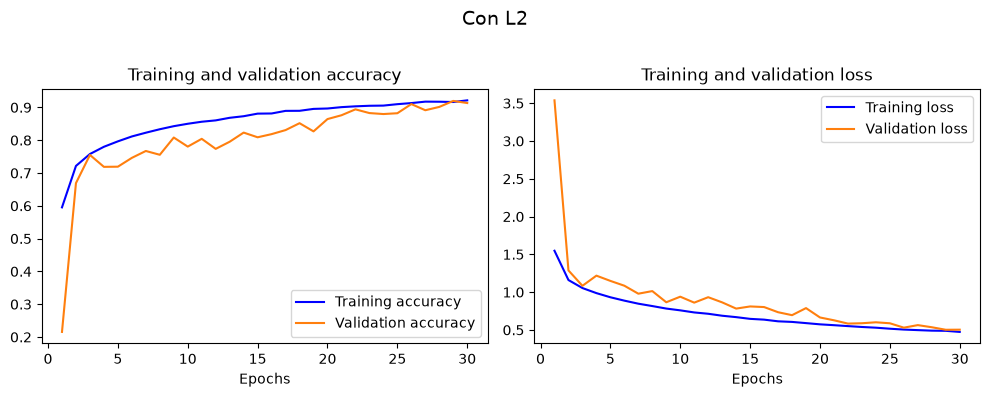

In [5]:
# CNN base con regularización L2
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "l2.keras")
model = crear_cnn(l2 = 1e-3)

model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Con L2", False, history.history, t0)
plot_curvas(history.history, "Con L2")

En esta gráfica se puede ver como añadiendo la regularización L2 los resultados de la base no mejoran significativamente. Esto se debe a que las otras técnicas utilizadas ya reducen el overfitting y , al ser un conjunto de datos reducido y una red sencilla, el uso de esta regularización no se puede apreciar mucho más que en el descenso mas suave de train loss. Aqui, penalizar los pesos grandes hace que la mejora del modelo se ralentice (underfitting) y eso causa el valor final más elevado de val loss comparado con la base. Para este problema en especifico, al no ver una mejora muy evidente, se ha optado por no utilizar esta regularización. 

Epoch 1/30
296/296 - 15s - 51ms/step - accuracy: 0.6458 - loss: 1.0101 - val_accuracy: 0.1119 - val_loss: 4.8568
Epoch 2/30
296/296 - 11s - 38ms/step - accuracy: 0.7759 - loss: 0.6477 - val_accuracy: 0.6286 - val_loss: 1.0113
Epoch 3/30
296/296 - 11s - 38ms/step - accuracy: 0.8077 - loss: 0.5520 - val_accuracy: 0.8252 - val_loss: 0.4995
Epoch 4/30
296/296 - 12s - 40ms/step - accuracy: 0.8321 - loss: 0.4904 - val_accuracy: 0.8459 - val_loss: 0.4393
Epoch 5/30
296/296 - 11s - 38ms/step - accuracy: 0.8502 - loss: 0.4446 - val_accuracy: 0.8175 - val_loss: 0.5092
Epoch 6/30
296/296 - 11s - 37ms/step - accuracy: 0.8599 - loss: 0.4130 - val_accuracy: 0.8449 - val_loss: 0.4325
Epoch 7/30
296/296 - 12s - 41ms/step - accuracy: 0.8725 - loss: 0.3812 - val_accuracy: 0.8264 - val_loss: 0.4895
Epoch 8/30
296/296 - 11s - 38ms/step - accuracy: 0.8792 - loss: 0.3578 - val_accuracy: 0.8758 - val_loss: 0.3705
Epoch 9/30
296/296 - 12s - 40ms/step - accuracy: 0.8894 - loss: 0.3339 - val_accuracy: 0.8657 - 

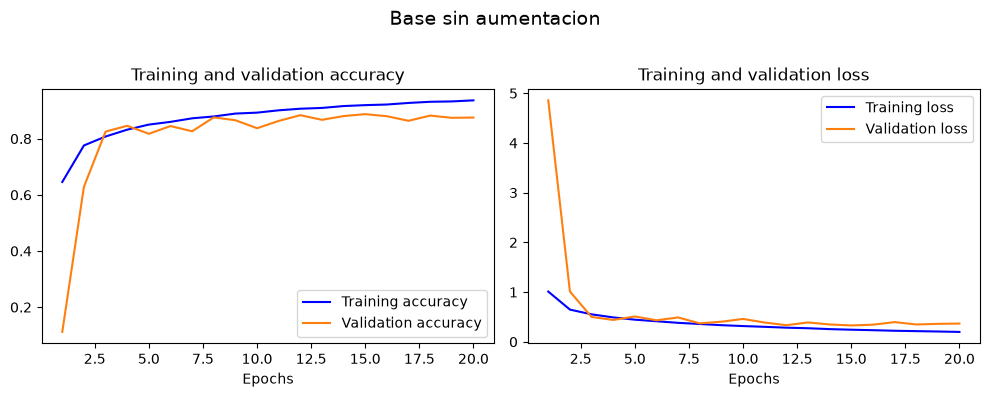

In [6]:
# CNN base sin aumentacion
reiniciar()
t0 = time.time() # Cronometra para medir el tiempo de entrenamiento

ruta = str(MODELOS / "sin_aumentacion.keras")
model = crear_cnn(aug=False)

model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Base sin aumentacion", False , history.history, t0)
plot_curvas(history.history, "Base sin aumentacion")

En estas gráficas se puede apreciar perfectamente el efecto de la aumentación. Si se comparan las curvas con la base, se ve que llega un punto en ellas en las que el loss llega a un mínimo y luego comienza a subir. Esto es un caso clarísimo de overfitting, donde el modelo se está aprendiendo el conjunto de train (que en este caso es mucho más reducido) en vez de aprender a extraer patrones de las imágenes al no tener suficientes ejemplos para caracterizar cada clase. El overfitting también se puede ver en el early stopping en la epoch 20, al no mejorar el val loss desde la 15, donde se alcanzó el pico del modelo. Aun en ese pico, la accuracy de train es de 0.895 y la de validación 0.8874, valores bastante más bajos que en la base. Esto demuestra la necesidad de diversificar el dataset en los casos en los que no hay un número suficiente de instancias para que el modelo sea capaz de generalizar patrones.

Epoch 1/30
296/296 - 15s - 52ms/step - accuracy: 0.5889 - loss: 1.2137 - val_accuracy: 0.1420 - val_loss: 3.3326
Epoch 2/30
296/296 - 13s - 43ms/step - accuracy: 0.7169 - loss: 0.8215 - val_accuracy: 0.7121 - val_loss: 0.8000
Epoch 3/30
296/296 - 12s - 40ms/step - accuracy: 0.7531 - loss: 0.6996 - val_accuracy: 0.7375 - val_loss: 0.8082
Epoch 4/30
296/296 - 12s - 40ms/step - accuracy: 0.7786 - loss: 0.6258 - val_accuracy: 0.7383 - val_loss: 0.8393
Epoch 5/30
296/296 - 21s - 72ms/step - accuracy: 0.7982 - loss: 0.5737 - val_accuracy: 0.7138 - val_loss: 0.9113
Epoch 6/30
296/296 - 12s - 41ms/step - accuracy: 0.8102 - loss: 0.5339 - val_accuracy: 0.8141 - val_loss: 0.5486
Epoch 7/30
296/296 - 13s - 44ms/step - accuracy: 0.8226 - loss: 0.5001 - val_accuracy: 0.8235 - val_loss: 0.5136
Epoch 8/30
296/296 - 12s - 40ms/step - accuracy: 0.8317 - loss: 0.4697 - val_accuracy: 0.8069 - val_loss: 0.5682
Epoch 9/30
296/296 - 12s - 41ms/step - accuracy: 0.8456 - loss: 0.4385 - val_accuracy: 0.8116 - 

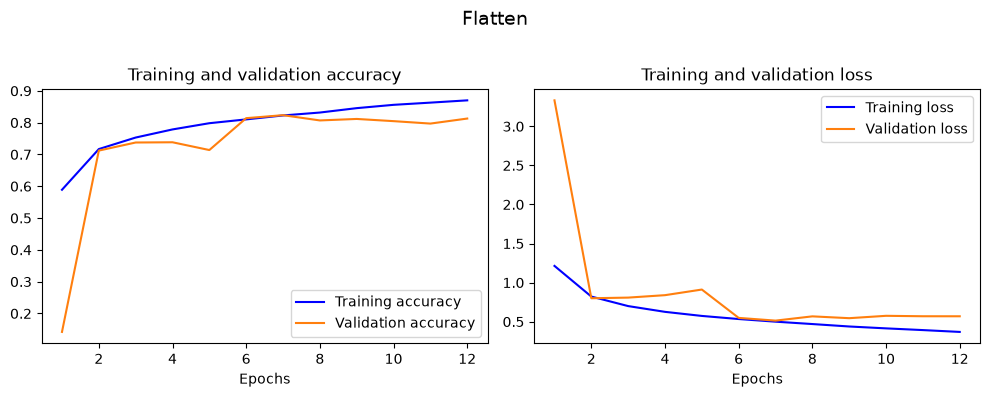

In [7]:
# CNN base con flatten 
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "flatten.keras")
model = crear_cnn(head="flatten")

model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Flatten", False, history.history, t0)
plot_curvas(history.history, "Flatten")

En esta gráfica se observa el efecto de sustituir el Global Average Pooling (GAP) por una capa Flatten. Al aplanar el vector de salida, en la conexión de salida (flatten -> dense) se genera una cantidad masiva de parámetros, lo que incrementa demasiado la capacidad del modelo y provoca overfitting a partir de la epoch 7. Este overfitting es más claro aun que en el caso de suprimir la aumentación, viendo una separación clara y creciente en las gráficas a partir del pico. Como consecuencia, el early stopping detiene el entrenamiento en una epoch muy temprana y demuestra que aplanar el vector en este caso únicamente consigue que el número de parámetros se dispare sin observar ninguna mejora comparandolo con la base (acc val de 0.823 frente a la de 0.917 de la base, casi 0.1 más).

Epoch 1/30
296/296 - 15s - 52ms/step - accuracy: 0.6585 - loss: 0.9973 - val_accuracy: 0.2138 - val_loss: 2.9863
Epoch 2/30
296/296 - 12s - 41ms/step - accuracy: 0.7673 - loss: 0.6719 - val_accuracy: 0.7057 - val_loss: 0.8099
Epoch 3/30
296/296 - 13s - 46ms/step - accuracy: 0.7989 - loss: 0.5842 - val_accuracy: 0.7802 - val_loss: 0.6546
Epoch 4/30
296/296 - 12s - 40ms/step - accuracy: 0.8172 - loss: 0.5327 - val_accuracy: 0.7595 - val_loss: 0.7123
Epoch 5/30
296/296 - 12s - 39ms/step - accuracy: 0.8303 - loss: 0.4892 - val_accuracy: 0.7565 - val_loss: 0.7266
Epoch 6/30
296/296 - 12s - 42ms/step - accuracy: 0.8472 - loss: 0.4495 - val_accuracy: 0.8212 - val_loss: 0.5270
Epoch 7/30
296/296 - 12s - 41ms/step - accuracy: 0.8576 - loss: 0.4215 - val_accuracy: 0.8146 - val_loss: 0.5295
Epoch 8/30
296/296 - 12s - 42ms/step - accuracy: 0.8641 - loss: 0.3985 - val_accuracy: 0.8430 - val_loss: 0.4659
Epoch 9/30
296/296 - 12s - 40ms/step - accuracy: 0.8757 - loss: 0.3718 - val_accuracy: 0.8489 - 

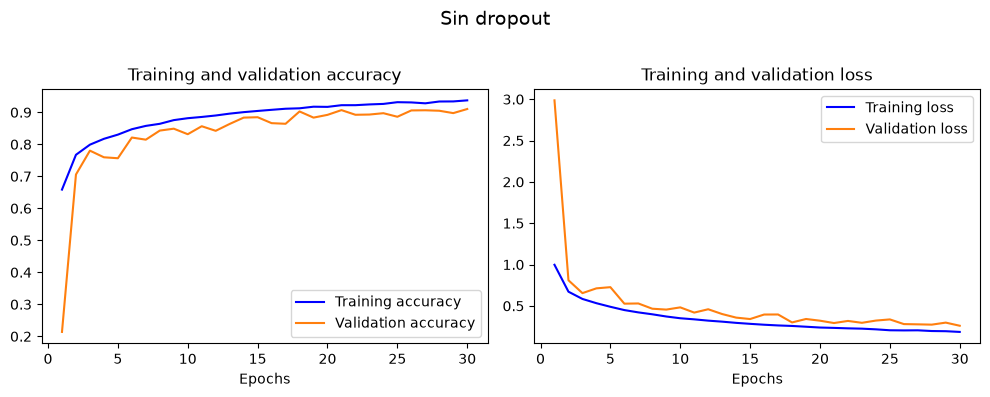

In [8]:
# CNN base sin dropout
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "sin_dropout.keras")
model = crear_cnn(dropout=0.0)

model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Sin dropout", False, history.history, t0)
plot_curvas(history.history, "Sin dropout")

Al comparar las curvas con la base original, se observa un ligero aumento de la brecha entre train y validación en las epochs finales (en la base es casi inexistente en la última). La diferencia es pequeña (ya que un dropout de 0.3 es ligero) pero se puede apreciar en las curvas de validación, que oscilan menos (las neuronas nunca se desactivan, se puede llegar a un overfitting en caso de redes más complejas). Debido a ello, se decidió mantener el dropout.

Epoch 1/30
296/296 - 14s - 48ms/step - accuracy: 0.6204 - loss: 1.0637 - val_accuracy: 0.2943 - val_loss: 2.3527
Epoch 2/30
296/296 - 11s - 39ms/step - accuracy: 0.7230 - loss: 0.7708 - val_accuracy: 0.5748 - val_loss: 1.2432
Epoch 3/30
296/296 - 11s - 38ms/step - accuracy: 0.7679 - loss: 0.6573 - val_accuracy: 0.6874 - val_loss: 0.9737
Epoch 4/30
296/296 - 11s - 38ms/step - accuracy: 0.8002 - loss: 0.5741 - val_accuracy: 0.6837 - val_loss: 0.9454
Epoch 5/30
296/296 - 12s - 39ms/step - accuracy: 0.8298 - loss: 0.4996 - val_accuracy: 0.7644 - val_loss: 0.6495
Epoch 6/30
296/296 - 11s - 39ms/step - accuracy: 0.8495 - loss: 0.4359 - val_accuracy: 0.7716 - val_loss: 0.6217
Epoch 7/30
296/296 - 11s - 38ms/step - accuracy: 0.8661 - loss: 0.3945 - val_accuracy: 0.7768 - val_loss: 0.6560
Epoch 8/30
296/296 - 11s - 38ms/step - accuracy: 0.8771 - loss: 0.3574 - val_accuracy: 0.7553 - val_loss: 0.6835
Epoch 9/30
296/296 - 11s - 37ms/step - accuracy: 0.8864 - loss: 0.3340 - val_accuracy: 0.8116 - 

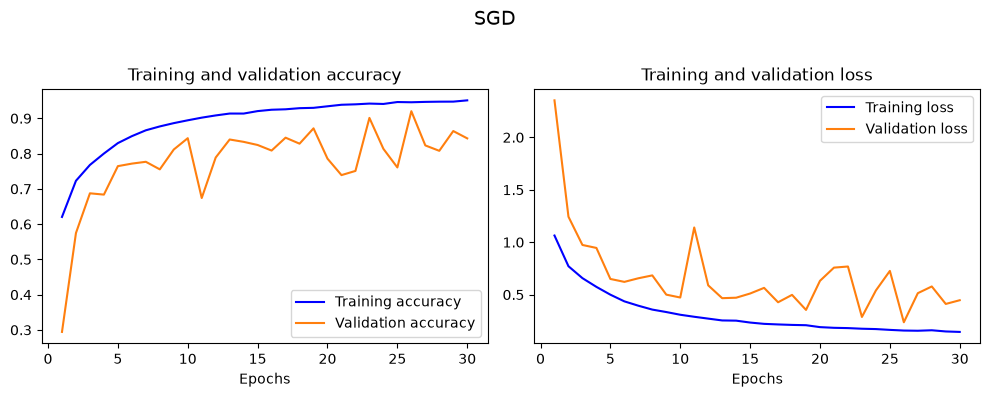

In [9]:
# CNN con SGD
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "sgd.keras")
model = crear_cnn()

# Mismo learning rate que Adam
model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum = 0.9), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "SGD", False, history.history, t0)
plot_curvas(history.history, "SGD")

En esta gráfica se sustituye el optimizador Adam por SGD con un learning rate de 0.01 (valor por defecto) y un momentum de 0.9. A diferencia de Adam, en las gráficas se observan picos muy pronunciados en la validación debidos, principalmente, al funcionamiento del optimizador, que oscila entre valores buscando el mínimo (en val loss). Al acercarse al mínimo, el momentum hace que el SGD rebote alrededor del óptimo en lugar de estabilizarse suavemente. El valor de 0.9 de momentum se eligió ya que, con valores más bajos, el early stopping detenía el entrenamiento al encontrar un mínimo local y no superarlo. Para intentar analizar mejor el comportamiento del optimizador, se optó por un valor más elevado.

Aun con el ruido, se obtuvieron resultados similares a la base. Esto demuestra que el SGD con momentum es capaz de alcanzar soluciones competitivas, pero depende de mecanismos como el Early Stopping para evitar que el modelo final se quede con un estado sobreajustado. Por ello, se decidió que Adam era el optimizador a utilizar.

### Comparación de arquitecturas
La red base tiene 3 bloques (Conv2d -> Batch Normalizaction -> ReLu) , con 32 filtros, un kernel de 3 x 3 y max pooling.
En esta sección se observan los resultados de aumentar y disminuir los valores de estos parámetros y de sustituír max pooling por una convolución con stride 2.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,794 (260.91 KB)

 Trainable params: 66,410 (259.41 KB)

 Non-trainable params: 384 (1.50 KB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/30
296/296 - 14s - 46ms/step - accuracy: 0.4775 - loss: 1.5268 - val_accuracy: 0.1136 - val_loss: 2.3860
Epoch 2/30
296/296 - 11s - 36ms/step - accuracy: 0.6161 - loss: 1.1436 - val_accuracy: 0.5983 - val_loss: 1.1555
Epoch 3/30
296/296 - 11s - 37ms/step - accuracy: 0.6541 - loss: 1.0215 - val_accuracy: 0.6205 - val_loss: 1.1341
Epoch 4/30
296/296 - 11s - 36ms/step - accuracy: 0.6842 - loss: 0.9393 - val_accuracy: 0.6311 - val_loss: 1.1313
Epoch 5/30
296/296 - 21s - 70ms/step - accuracy: 0.6986 - loss: 0.8862 - val_accuracy: 0.6704 - val_loss: 0.9904
Epoch 6/30
296/296 - 11s - 36ms/step - accuracy: 0.7174 - loss: 0.8324 - val_accuracy: 0.6380 - val_loss: 1.1266
Epoch 7/30
296/296 - 11s - 36ms/step - accuracy: 0.7240 - loss: 0.8131 - val_accuracy: 0.6672 - val_loss: 0.9718
Epoch 8/30
296/296 - 11s - 36ms/step - accuracy: 0.7349 - loss: 0.7755 - val_accuracy: 0.6481 - val_loss: 1.1042
Epoch 9/30
296/296 - 11s - 36ms/step - accuracy: 0.7472 - loss: 0.7447 - val_accuracy: 0.6911 - 

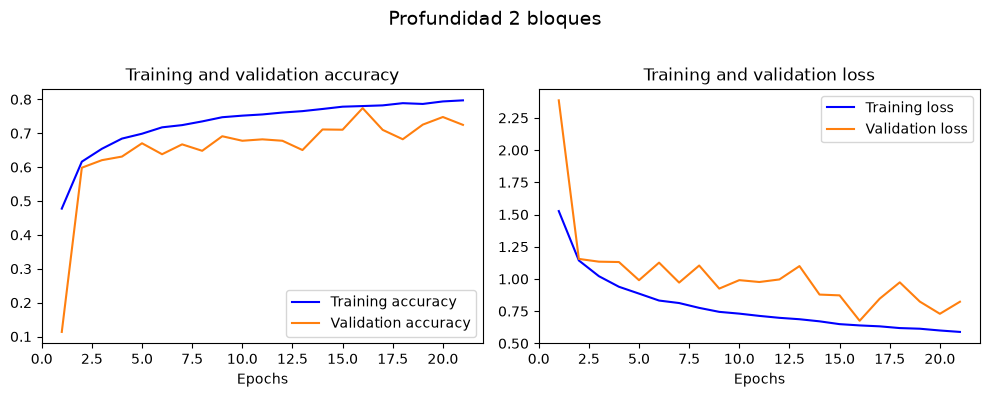

In [10]:
# 2 bloques
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "profundidad_2.keras")
model = crear_cnn(n_bloques=2)

model.summary()
visualkeras.layered_view(model, legend=True)

model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Profundidad 2 bloques", False, history.history, t0)
plot_curvas(history.history, "Profundidad 2 bloques")

En este experimento, se elimina uno de los bloques para observar el efecto que tiene en el aprendizaje de la red. Se ve claramente como, con únicamente 2 bloques, el modelo tiene problemas para aprender los patrones de cada clase (underfitting).

Esto se ve sobre todo en el train accuracy, que únicamente llega a 0.779 y se estabiliza sobre esos valores, cuando en la base (3 bloques) se estabilizaba alrededor de 0.9 (en validación pasa lo mismo). El loss también es mucho más alto en ambos conjuntos, y se ve como, al no aprender a identificar patrones, la curva de validation oscila (el modelo es muy sensible a la variación en los datos).

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,177,706 (4.49 MB)

 Trainable params: 1,175,786 (4.49 MB)

 Non-trainable params: 1,920 (7.50 KB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/30
296/296 - 19s - 64ms/step - accuracy: 0.6712 - loss: 0.9364 - val_accuracy: 0.1237 - val_loss: 5.8660
Epoch 2/30
296/296 - 14s - 47ms/step - accuracy: 0.7656 - loss: 0.6572 - val_accuracy: 0.7464 - val_loss: 0.7195
Epoch 3/30
296/296 - 14s - 46ms/step - accuracy: 0.8022 - loss: 0.5637 - val_accuracy: 0.8163 - val_loss: 0.5402
Epoch 4/30
296/296 - 13s - 46ms/step - accuracy: 0.8196 - loss: 0.5154 - val_accuracy: 0.8207 - val_loss: 0.5401
Epoch 5/30
296/296 - 21s - 70ms/step - accuracy: 0.8418 - loss: 0.4553 - val_accuracy: 0.8081 - val_loss: 0.5574
Epoch 6/30
296/296 - 13s - 45ms/step - accuracy: 0.8578 - loss: 0.4081 - val_accuracy: 0.8415 - val_loss: 0.4525
Epoch 7/30
296/296 - 13s - 46ms/step - accuracy: 0.8708 - loss: 0.3796 - val_accuracy: 0.8398 - val_loss: 0.4590
Epoch 8/30
296/296 - 14s - 46ms/step - accuracy: 0.8778 - loss: 0.3520 - val_accuracy: 0.8575 - val_loss: 0.4069
Epoch 9/30
296/296 - 13s - 45ms/step - accuracy: 0.8888 - loss: 0.3215 - val_accuracy: 0.8380 - 

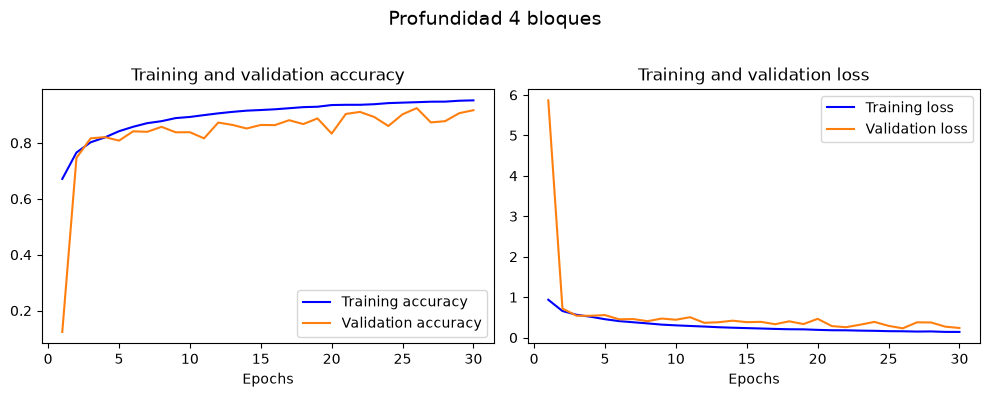

In [11]:
# 4 bloques
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "profundidad_4.keras")
model = crear_cnn(n_bloques=4)

model.summary()
visualkeras.layered_view(model, legend=True)

model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Profundidad 4 bloques", False, history.history, t0)
plot_curvas(history.history, "Profundidad 4 bloques")

En este experimento se aumenta la arquitectura a 4 bloques. A diferencia de la reducción a 2 bloques (que causaba underfitting), en este caso el problema es el contrario. La red adquiere una capacidad excesiva, lo que se refleja en una diferencia creciente entre la accuracy de entrenamiento y la de validación.

Además, al aplicar 4 operaciones de max pooling, el mapa de características final se reduce a 4x4, lo que provoca una pérdida excesiva de información (se puede ver en la gráfica de loss, que cae de golpe y comienza a oscilar en vez de seguir mejorando). Por tanto, se concluye que 4 bloques es una profundidad excesiva para este problema.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │             

 Total params: 73,402 (286.73 KB)

 Trainable params: 72,954 (284.98 KB)

 Non-trainable params: 448 (1.75 KB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/30
296/296 - 10s - 34ms/step - accuracy: 0.4800 - loss: 1.5396 - val_accuracy: 0.1644 - val_loss: 2.3591
Epoch 2/30
296/296 - 7s - 24ms/step - accuracy: 0.6353 - loss: 1.0830 - val_accuracy: 0.6104 - val_loss: 1.1141
Epoch 3/30
296/296 - 7s - 25ms/step - accuracy: 0.6923 - loss: 0.9244 - val_accuracy: 0.6795 - val_loss: 0.9419
Epoch 4/30
296/296 - 7s - 23ms/step - accuracy: 0.7149 - loss: 0.8474 - val_accuracy: 0.6886 - val_loss: 0.9062
Epoch 5/30
296/296 - 7s - 25ms/step - accuracy: 0.7337 - loss: 0.7983 - val_accuracy: 0.6938 - val_loss: 0.8893
Epoch 6/30
296/296 - 7s - 23ms/step - accuracy: 0.7461 - loss: 0.7598 - val_accuracy: 0.6812 - val_loss: 0.9208
Epoch 7/30
296/296 - 7s - 23ms/step - accuracy: 0.7541 - loss: 0.7285 - val_accuracy: 0.7141 - val_loss: 0.8319
Epoch 8/30
296/296 - 7s - 23ms/step - accuracy: 0.7614 - loss: 0.7067 - val_accuracy: 0.6916 - val_loss: 0.9090
Epoch 9/30
296/296 - 7s - 23ms/step - accuracy: 0.7692 - loss: 0.6808 - val_accuracy: 0.6869 - val_loss

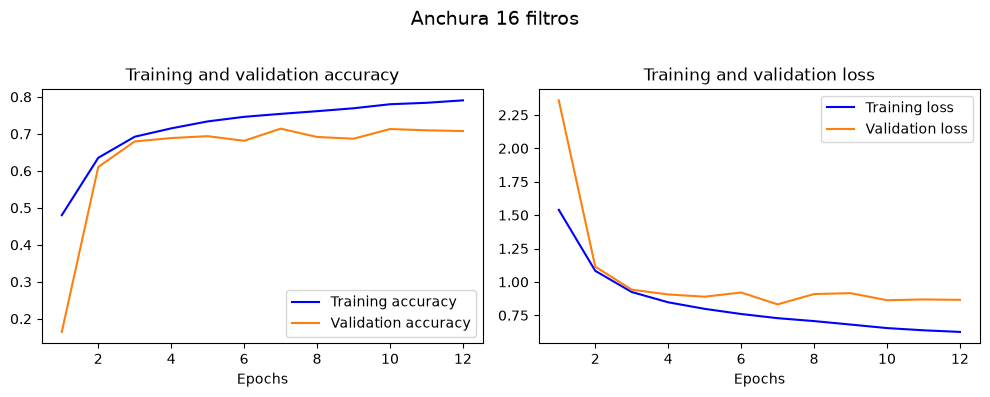

In [12]:
# 16 filtros (menos capacidad)
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "anchura_16.keras")
model = crear_cnn(filtros=16)

model.summary()
visualkeras.layered_view(model, legend=True)

model.compile(optimizer=keras.optimizers.Adam(1e-4),loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Anchura 16 filtros", False, history.history, t0)
plot_curvas(history.history, "Anchura 16 filtros")

Esta gráfica representa un caso extremo de underfitting, donde se llega a un pico (en este caso la época 7) y a partir de ahi, validación se estanca mientras train mejora muy ligeramente. Esto está dado ya que con 16 filtros el modelo tiene muy poca capacidad de reconocimiento de patrones y no ha conseguido distinguir clases similares entre sí, por lo que el train accuracy mejora lentamente hasta 0.8 mientras que en validación se estanca en 0.7. Por eso se concluye que este número de filtros es demasiado bajo para el dataset a analizar.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,150,666 (4.39 MB)

 Trainable params: 1,148,874 (4.38 MB)

 Non-trainable params: 1,792 (7.00 KB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/30
296/296 - 31s - 104ms/step - accuracy: 0.6668 - loss: 0.9427 - val_accuracy: 0.1210 - val_loss: 4.3240
Epoch 2/30
296/296 - 26s - 88ms/step - accuracy: 0.7568 - loss: 0.6865 - val_accuracy: 0.5336 - val_loss: 1.3287
Epoch 3/30
296/296 - 26s - 89ms/step - accuracy: 0.7882 - loss: 0.6056 - val_accuracy: 0.7067 - val_loss: 0.8686
Epoch 4/30
296/296 - 26s - 89ms/step - accuracy: 0.8113 - loss: 0.5413 - val_accuracy: 0.6699 - val_loss: 0.9916
Epoch 5/30
296/296 - 41s - 139ms/step - accuracy: 0.8262 - loss: 0.4964 - val_accuracy: 0.7202 - val_loss: 0.8507
Epoch 6/30
296/296 - 26s - 89ms/step - accuracy: 0.8447 - loss: 0.4429 - val_accuracy: 0.7575 - val_loss: 0.7159
Epoch 7/30
296/296 - 26s - 88ms/step - accuracy: 0.8578 - loss: 0.4066 - val_accuracy: 0.7030 - val_loss: 0.8695
Epoch 8/30
296/296 - 26s - 88ms/step - accuracy: 0.8661 - loss: 0.3857 - val_accuracy: 0.8225 - val_loss: 0.5218
Epoch 9/30
296/296 - 26s - 88ms/step - accuracy: 0.8784 - loss: 0.3518 - val_accuracy: 0.7854 

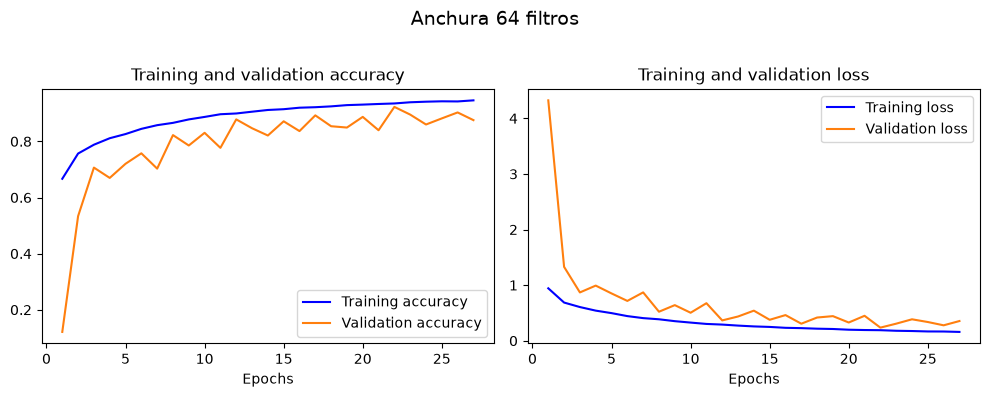

In [13]:
# 64 filtros (más capacidad)
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "anchura_64.keras")
model = crear_cnn(filtros=64)

model.summary()
visualkeras.layered_view(model, legend=True)

model.compile(optimizer=keras.optimizers.Adam(1e-4),loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Anchura 64 filtros", False, history.history, t0)
plot_curvas(history.history, "Anchura 64 filtros")

Aquí se ve el efecto de duplicar los filtros de la base. Se ve como train y validación dan muy buenos resultados en pocas epochs. Esto se debe a que, con más filtros, el modelo aprende a detectar patrones más complejos. Los picos que se ven en validación probablemente correspondan a la diferencia entre el elevado número de parámetros del modelo en comparación con las pocas muestras del conjunto de validación, pero no se percibe overfitting. 

Sin embargo, comparado con la base, este modelo ha tardado el doble de tiempo de entrenamiento debido a su complejidad (7 minutos para 30 epochs contra 13 minutos para 27). La mejora en métricas finales no es tan significativa como para justificar esa diferencia (0.923 en validación frente a los 0.917 de la base), por lo que se mantiene la decisión de mantener la base.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,72

 Total params: 484,074 (1.85 MB)

 Trainable params: 482,730 (1.84 MB)

 Non-trainable params: 1,344 (5.25 KB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/30
296/296 - 19s - 66ms/step - accuracy: 0.6118 - loss: 1.1642 - val_accuracy: 0.1185 - val_loss: 3.3100
Epoch 2/30
296/296 - 15s - 50ms/step - accuracy: 0.7323 - loss: 0.7856 - val_accuracy: 0.6960 - val_loss: 0.8407
Epoch 3/30
296/296 - 15s - 50ms/step - accuracy: 0.7757 - loss: 0.6607 - val_accuracy: 0.7973 - val_loss: 0.5937
Epoch 4/30
296/296 - 15s - 50ms/step - accuracy: 0.8008 - loss: 0.5918 - val_accuracy: 0.8136 - val_loss: 0.5670
Epoch 5/30
296/296 - 20s - 69ms/step - accuracy: 0.8195 - loss: 0.5319 - val_accuracy: 0.8081 - val_loss: 0.5704
Epoch 6/30
296/296 - 15s - 50ms/step - accuracy: 0.8368 - loss: 0.4861 - val_accuracy: 0.8178 - val_loss: 0.5164
Epoch 7/30
296/296 - 15s - 49ms/step - accuracy: 0.8477 - loss: 0.4560 - val_accuracy: 0.8198 - val_loss: 0.5386
Epoch 8/30
296/296 - 15s - 50ms/step - accuracy: 0.8567 - loss: 0.4281 - val_accuracy: 0.8533 - val_loss: 0.4314
Epoch 9/30
296/296 - 15s - 49ms/step - accuracy: 0.8622 - loss: 0.4054 - val_accuracy: 0.8333 - 

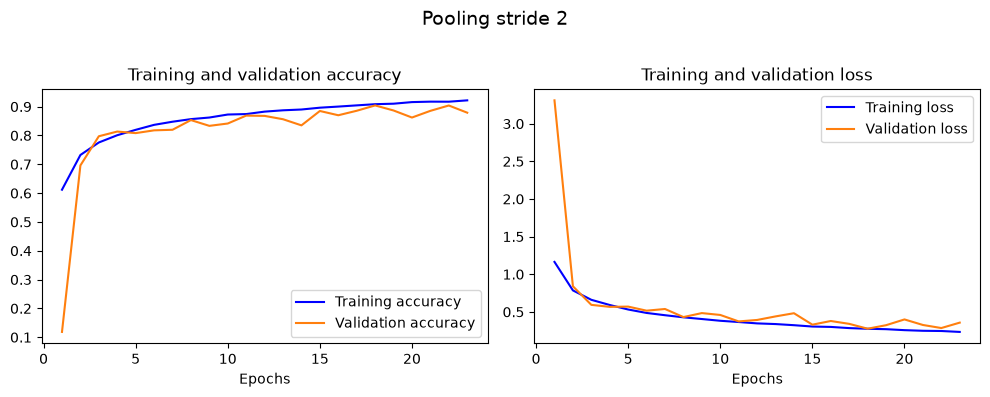

In [14]:
# convolución con stride 2 en vez de MaxPool
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "pooling_stride.keras")
model = crear_cnn(pooling="stride")

model.summary()
visualkeras.layered_view(model, legend=True)

model.compile(optimizer=keras.optimizers.Adam(1e-4),loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),epochs=30, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Pooling stride 2", False, history.history, t0)
plot_curvas(history.history, "Pooling stride 2")

En esta gráfica se muestra el efecto de sustituir el MaxPooling por una convolución con stride 2, una técnica que permite a la red aprender el proceso de downsampling en lugar de usar una operación fija. Los resultados muestran un rendimiento muy similar al de la base (la validación se mantiene alrededor de 0.9) y las curvas no presentan overfitting.

Aquí, la mejora de flexibilidad de la convolución no se puede apreciar muy claramente, ya que para este problema, el max pooling es suficiente. Al sustituirlo por una convolución, se añade casi el doble de parámetros (282000 vs 484000 aproximadamente) sin una ganancia significativa en la capacidad del modelo.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │        25,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        51,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │       102,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │       204,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       409,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 799,082 (3.05 MB)

 Trainable params: 798,186 (3.04 MB)

 Non-trainable params: 896 (3.50 KB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/30
296/296 - 21s - 69ms/step - accuracy: 0.6467 - loss: 1.0293 - val_accuracy: 0.1427 - val_loss: 3.6069
Epoch 2/30
296/296 - 17s - 57ms/step - accuracy: 0.7406 - loss: 0.7419 - val_accuracy: 0.6360 - val_loss: 1.0697
Epoch 3/30
296/296 - 17s - 56ms/step - accuracy: 0.7730 - loss: 0.6551 - val_accuracy: 0.7136 - val_loss: 0.8100
Epoch 4/30
296/296 - 17s - 57ms/step - accuracy: 0.7910 - loss: 0.5961 - val_accuracy: 0.7378 - val_loss: 0.7555
Epoch 5/30
296/296 - 21s - 70ms/step - accuracy: 0.8101 - loss: 0.5464 - val_accuracy: 0.7375 - val_loss: 0.7469
Epoch 6/30
296/296 - 17s - 56ms/step - accuracy: 0.8243 - loss: 0.5066 - val_accuracy: 0.7368 - val_loss: 0.8529
Epoch 7/30
296/296 - 17s - 56ms/step - accuracy: 0.8339 - loss: 0.4789 - val_accuracy: 0.7432 - val_loss: 0.8069
Epoch 8/30
296/296 - 17s - 56ms/step - accuracy: 0.8476 - loss: 0.4423 - val_accuracy: 0.7272 - val_loss: 0.8566
Epoch 9/30
296/296 - 17s - 57ms/step - accuracy: 0.8584 - loss: 0.4120 - val_accuracy: 0.7889 - 

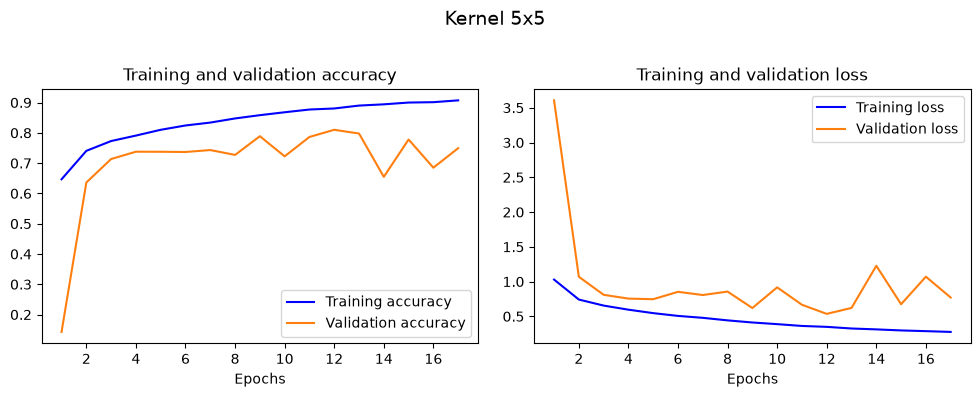

In [15]:
# Kernel 5x5 
reiniciar()
t0 = time.time()

ruta = str(MODELOS / "kernel_5.keras")
model = crear_cnn(kernel=5)

model.summary()
visualkeras.layered_view(model, legend=True)

model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),epochs=30, batch_size=64,callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "Kernel 5x5", False, history.history, t0)
plot_curvas(history.history, "Kernel 5x5")

En esta gráfica se muestra el efecto de aumentar el tamaño del kernel a 5x5 en todas las capas. Las gráficas revelan una gran inestabilidad en el entrenamiento: la curva de validación presenta picos muy pronunciados, a pesar de que la train accuracy siga subiendo hasta llegar a 0.90. Esto indica que la red presenta overfitting y además es muy sensible a las variaciones del conjunto de validación.

El aumento del tamaño del kernel incrementa el número de parámetros desde las primeras capas, lo que añade mucha complejidad y coste computacional (casi el doble de tiempo por época) sin mejorar la generalización. Por tanto, se concluye que el kernel 3x3 de la base se comporta mejor para este problema.

### CNNs Pre entrenadas

Al utilizar redes preentrenadas, la parte convolucional ya ha aprendido a extraer características visuales generales. Por ello, se reduce el número de épocas a 10 (en vez de las 30 anteriores) para que el modelo se centre únicamente en ajustar la cabeza de clasificación a las nuevas clases, en lugar de tener que entrenar toda la red desde cero.
Para el feature extraction solo se entrena la cabeza de clasificación nueva que se añade al final mientras que para el fine tuning se descongelan las últimas capas (últimas 30, en este caso) y se entrenan de nuevo con un learning rate bajo para no destruir los pesos anteriores.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 3, 3, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,302,474 (27.86 MB)

 Trainable params: 264,970 (1.01 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

/home/snesh/AP/ap/lib/python3.12/site-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


Epoch 1/10
296/296 - 29s - 99ms/step - accuracy: 0.6988 - loss: 0.9928 - val_accuracy: 0.8704 - val_loss: 0.4576
Epoch 2/10
296/296 - 16s - 53ms/step - accuracy: 0.8698 - loss: 0.4198 - val_accuracy: 0.9005 - val_loss: 0.3316
Epoch 3/10
296/296 - 16s - 53ms/step - accuracy: 0.8897 - loss: 0.3393 - val_accuracy: 0.9158 - val_loss: 0.2787
Epoch 4/10
296/296 - 16s - 53ms/step - accuracy: 0.9063 - loss: 0.2910 - val_accuracy: 0.9178 - val_loss: 0.2598
Epoch 5/10
296/296 - 15s - 52ms/step - accuracy: 0.9103 - loss: 0.2672 - val_accuracy: 0.9262 - val_loss: 0.2392
Epoch 6/10
296/296 - 21s - 70ms/step - accuracy: 0.9165 - loss: 0.2537 - val_accuracy: 0.9235 - val_loss: 0.2364
Epoch 7/10
296/296 - 16s - 52ms/step - accuracy: 0.9202 - loss: 0.2355 - val_accuracy: 0.9257 - val_loss: 0.2347
Epoch 8/10
296/296 - 16s - 53ms/step - accuracy: 0.9231 - loss: 0.2306 - val_accuracy: 0.9264 - val_loss: 0.2218
Epoch 9/10
296/296 - 15s - 52ms/step - accuracy: 0.9255 - loss: 0.2195 - val_accuracy: 0.9296 - 

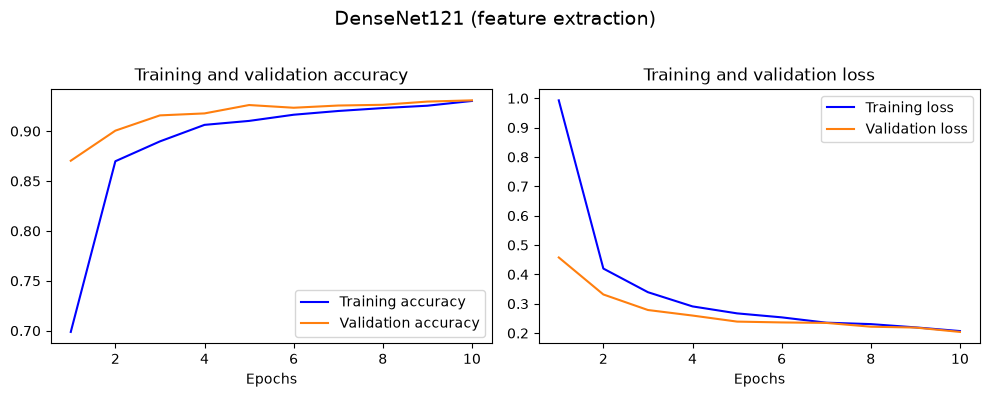

In [16]:
# DENSENET121 FEATURE EXTRACTION
reiniciar()
t0 = time.time()

model, conv_base = crear_preentrenado("DenseNet121")
ruta = str(MODELOS / "densenet121_fe.keras")

model.summary()
visualkeras.layered_view(model, legend=True)

model.compile(optimizer=keras.optimizers.Adam(1e-4),loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_fe = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "DenseNet121 (feature extraction)", True, history_fe.history, t0)
plot_curvas(history_fe.history, "DenseNet121 (feature extraction)")

En esta gráfica se muestra el entrenamiento de DenseNet121 utilizando la estrategia de Feature Extraction. Se observa un fenómeno característico del transfer learning que se va a observar en el resto de gráficas de redes preeentrenadas: durante las primeras épocas, la accuracy de validación es mejor que la de entrenamiento. Esto se debe a tres factores: la presencia de Dropout en la cabeza de clasificación, que se desactiva en validación, el uso de Batch Normalization, que utiliza estadísticas más precisas durante la inferencia y el hecho de que la red ya está entrenada con ImageNet, por lo que generaliza bien desde el principio.

A medida que avanzan las épocas, ambas curvas convergen hasta alcanzar un valor de 0.941 en train y 0.930 en validación, sin presentar overfitting. Este resultado, obtenido en solo 10 epochs, demuestra la ventaja de partir de pesos preentrenados frente a entrenar una CNN desde cero, tanto en rendimiento final como en eficiencia temporal (únicamente 3 minutos).

Epoch 1/10
296/296 - 34s - 115ms/step - accuracy: 0.9345 - loss: 0.1995 - val_accuracy: 0.9319 - val_loss: 0.2062
Epoch 2/10
296/296 - 19s - 64ms/step - accuracy: 0.9333 - loss: 0.1920 - val_accuracy: 0.9331 - val_loss: 0.2015
Epoch 3/10
296/296 - 19s - 64ms/step - accuracy: 0.9354 - loss: 0.1895 - val_accuracy: 0.9326 - val_loss: 0.2015
Epoch 4/10
296/296 - 19s - 63ms/step - accuracy: 0.9356 - loss: 0.1885 - val_accuracy: 0.9336 - val_loss: 0.1981
Epoch 5/10
296/296 - 19s - 63ms/step - accuracy: 0.9383 - loss: 0.1799 - val_accuracy: 0.9358 - val_loss: 0.1958
Epoch 6/10
296/296 - 19s - 63ms/step - accuracy: 0.9408 - loss: 0.1768 - val_accuracy: 0.9368 - val_loss: 0.1927
Epoch 7/10
296/296 - 19s - 63ms/step - accuracy: 0.9416 - loss: 0.1715 - val_accuracy: 0.9380 - val_loss: 0.1879
Epoch 8/10
296/296 - 19s - 63ms/step - accuracy: 0.9403 - loss: 0.1719 - val_accuracy: 0.9380 - val_loss: 0.1855
Epoch 9/10
296/296 - 21s - 70ms/step - accuracy: 0.9427 - loss: 0.1724 - val_accuracy: 0.9368 -

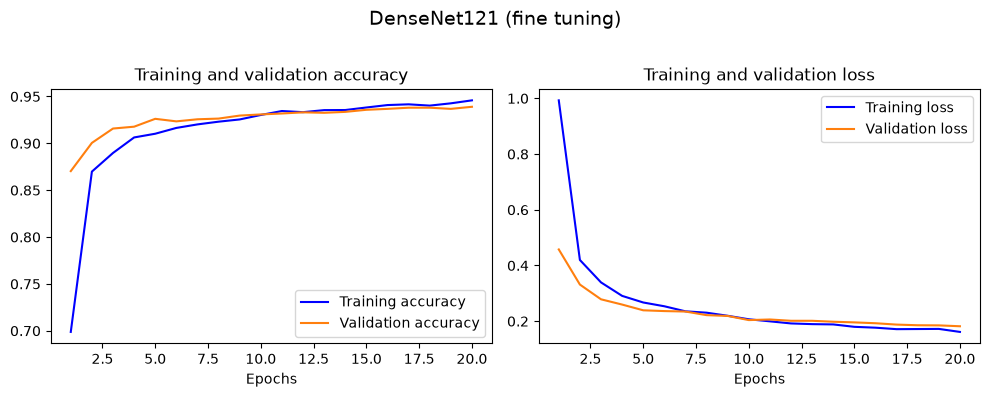

In [17]:
# DENSENET121 FINE TUNING
conv_base.trainable = True
for layer in conv_base.layers[:-30]:
    layer.trainable = False

ruta = str(MODELOS / "densenet121_ft.keras")
# Se usa 1e-5 , lr más bajo que en feature extraction
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

historial_completo = {k: history_fe.history.get(k, []) + history_ft.history.get(k, []) for k in set(history_fe.history) | set(history_ft.history)}
resultado = evaluar(ruta, "DenseNet121 (fine tuning)", True, historial_completo, t0, desde=len(history_fe.history["val_loss"]))
plot_curvas(historial_completo, "DenseNet121 (fine tuning)")

En fine tuning se parte de la base de feature extraction, por lo que las primeras 10 epochs corresponden con las de la gráfica anterior. Con fine tuning, se ve como el modelo sigue mejorando en train (de 0.941 a 0.952 de accuracy) pero se estanca en validación. Esto se debe a que, al liberar las capas, la red descongela muchos parámetros con los que memoriza las imágenes de train, lo que causa la ligera mejora de train sobre validación que se aprecia a partir de la epoch 10.  

Epoch 1/10
296/296 - 23s - 77ms/step - accuracy: 0.8017 - loss: 0.6424 - val_accuracy: 0.9052 - val_loss: 0.3188
Epoch 2/10
296/296 - 15s - 51ms/step - accuracy: 0.9042 - loss: 0.2935 - val_accuracy: 0.9210 - val_loss: 0.2509
Epoch 3/10
296/296 - 15s - 49ms/step - accuracy: 0.9181 - loss: 0.2495 - val_accuracy: 0.9277 - val_loss: 0.2334
Epoch 4/10
296/296 - 14s - 49ms/step - accuracy: 0.9259 - loss: 0.2218 - val_accuracy: 0.9304 - val_loss: 0.2194
Epoch 5/10
296/296 - 15s - 50ms/step - accuracy: 0.9304 - loss: 0.2041 - val_accuracy: 0.9341 - val_loss: 0.2151
Epoch 6/10
296/296 - 15s - 51ms/step - accuracy: 0.9349 - loss: 0.1916 - val_accuracy: 0.9358 - val_loss: 0.2147
Epoch 7/10
296/296 - 15s - 49ms/step - accuracy: 0.9390 - loss: 0.1811 - val_accuracy: 0.9383 - val_loss: 0.2003
Epoch 8/10
296/296 - 14s - 47ms/step - accuracy: 0.9387 - loss: 0.1781 - val_accuracy: 0.9385 - val_loss: 0.2043
Epoch 9/10
296/296 - 14s - 47ms/step - accuracy: 0.9422 - loss: 0.1698 - val_accuracy: 0.9360 - 

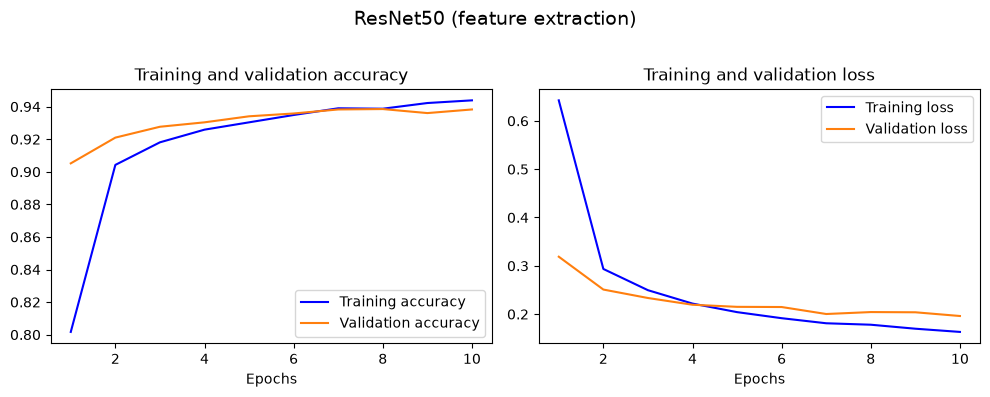

In [18]:
# Resnet feature extraction
reiniciar()
t0 = time.time()

model, conv_base = crear_preentrenado("ResNet50")
ruta = str(MODELOS / "resnet50_fe.keras")

model.compile(optimizer=keras.optimizers.Adam(1e-4),loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_fe = model.fit(X_train, y_train, validation_data=(X_val, y_val),epochs=10, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

resultado = evaluar(ruta, "ResNet50 (feature extraction)", True, history_fe.history, t0)
plot_curvas(history_fe.history, "ResNet50 (feature extraction)")

En feature extraction de Resnet se puede apreciar el mismo fenómeno que en Densenet, las métricas de validación superan a las de train, pero en este caso solo en las primeras épocas. Con Resnet se llega a valores ligeramente más altos de accuracy aunque similares de loss a costa de ver un pequeño overfitting a partir de la época 7/8. Esta gráfica justifica la decisión de detener el entrenamiento de las redes preentrenadas en 10 epochs en vez de dejarles las 30 de las CNN propias porque, como se ve, al estar ya entrenadas y tener muchos parámetros, en este dataset siempre se llega a un punto en el que la red se aprende el conjunto de train (mucho antes de lo que se provoca el overfitting en las propias).

Epoch 1/10
296/296 - 32s - 108ms/step - accuracy: 0.9496 - loss: 0.1428 - val_accuracy: 0.9420 - val_loss: 0.1805
Epoch 2/10
296/296 - 22s - 76ms/step - accuracy: 0.9562 - loss: 0.1242 - val_accuracy: 0.9437 - val_loss: 0.1749
Epoch 3/10
296/296 - 41s - 137ms/step - accuracy: 0.9583 - loss: 0.1211 - val_accuracy: 0.9464 - val_loss: 0.1672
Epoch 4/10
296/296 - 22s - 74ms/step - accuracy: 0.9621 - loss: 0.1084 - val_accuracy: 0.9504 - val_loss: 0.1638
Epoch 5/10
296/296 - 22s - 75ms/step - accuracy: 0.9649 - loss: 0.1034 - val_accuracy: 0.9519 - val_loss: 0.1629
Epoch 6/10
296/296 - 22s - 74ms/step - accuracy: 0.9688 - loss: 0.0926 - val_accuracy: 0.9501 - val_loss: 0.1593
Epoch 7/10
296/296 - 22s - 74ms/step - accuracy: 0.9676 - loss: 0.0917 - val_accuracy: 0.9531 - val_loss: 0.1530
Epoch 8/10
296/296 - 22s - 74ms/step - accuracy: 0.9724 - loss: 0.0818 - val_accuracy: 0.9543 - val_loss: 0.1479
Epoch 9/10
296/296 - 21s - 71ms/step - accuracy: 0.9725 - loss: 0.0790 - val_accuracy: 0.9514 

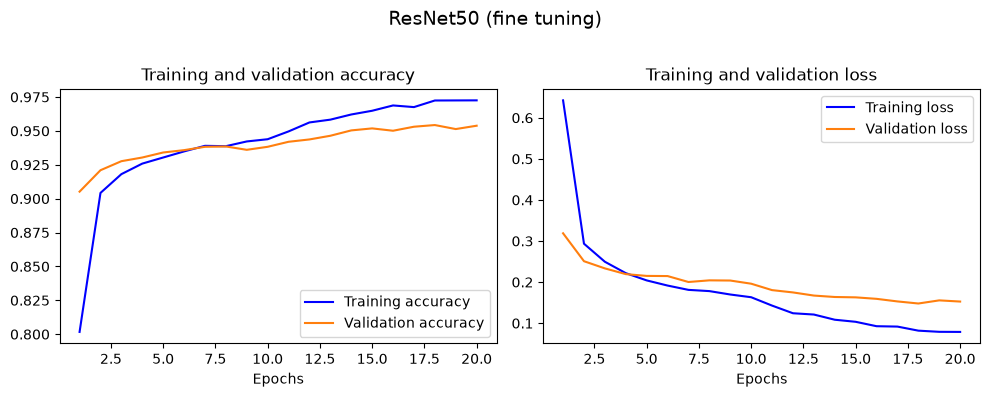

In [19]:
# Resnet fine tuning
conv_base.trainable = True
for layer in conv_base.layers[:-30]:
    layer.trainable = False

ruta = str(MODELOS / "resnet50_ft.keras")
# Se usa 1e-5 , lr más bajo que en feature extraction
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64, callbacks=crear_callbacks(ruta), verbose=2)

historial_completo = {k: history_fe.history.get(k, []) + history_ft.history.get(k, []) for k in set(history_fe.history) | set(history_ft.history)}
resultado = evaluar(ruta, "ResNet50 (fine tuning)", True, historial_completo, t0, desde=len(history_fe.history["val_loss"]))
plot_curvas(historial_completo, "ResNet50 (fine tuning)")

En esta red se puede ver mucho mejor el overfitting que causa el fine tuning comparado con el feature extraction. Se ve el salto enorme en las métricas de train a partir de la epoch 10, la cual ya contaba con overfitting. El overfitting se hace mucho más claro, al estar modificando pesos que ya estaban provocando sobreentrenamiento. Vemos que la acurracy de train es la más alta de todas las vistas (0.9801) pero la de validation no aumenta más que 0.02 respecto a feature extraction. 

Habiendo visto el resultado del fine tuning en ambas redes preentrenadas, se concluye que, para este dataset , únicamente mejora los resultados ya que sobrecomplica el problema.